In [52]:
from astropy.io import fits
from astropy.visualization import ZScaleInterval
import astropy.coordinates as coord
from astropy.wcs import WCS
import astropy.units as u
from astroquery.vizier import Vizier
from scipy.optimize import curve_fit
from scipy.spatial.distance import cdist
from scipy.ndimage import label
from glob import glob
import cmastro
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
import pprint
plt.rcParams['image.origin'] = 'upper'

Useful functions for working with .fits files

In [53]:
def read_file(filename):
    image = fits.open("{f}".format(f=filename))[0].data.astype(int)
    return image

def header(filename):
    header = fits.open("{f}".format(f=filename))[0].header
    return header

def view(image, title, c = 'gray'):
    fig = plt.figure(figsize=(24, 12))
    vmin, vmax = ZScaleInterval().get_limits(image)
    plt.imshow(image, vmin=vmin, vmax=vmax, origin='lower', cmap=c)
    plt.title(title)
    plt.colorbar()
    plt.rcParams['image.origin'] = 'upper'
    plt.show()

def get_and_sort_files(folder, extension = 'fts'):
    # Get all .fts files
    files = [y for x in os.walk(folder) for y in glob(os.path.join(x[0], '*.' + extension))]

    # Pick out types of images and sort
    asteroid_files = [f for f in files if "26Proserpina-" in f]
    ast_headers = [header(f) for f in asteroid_files]
    flat_files = [f for f in files if "Flat" in f]
    dark_files = [f for f in files if "Dark" in f]
    bias_files = [f for f in files if "Bias" in f]
    asteroid_files.sort()
    flat_files.sort() 
    dark_files.sort() 
    bias_files.sort()
    return asteroid_files, ast_headers, flat_files, dark_files, bias_files   

**1. Get images categorized by date and type**

In [54]:
# 4 obs nights, 3 astroid images each
folder = "26Proserpina/"
observations = ["20120119", "20120120", "20120122", "20120125"]

# Images paths for each obs night
asteroid1, headers1, flats1, darks1, biases1 = get_and_sort_files(folder + observations[0])
asteroid2, headers2, flats2, darks2, biases2 = get_and_sort_files(folder + observations[1])
asteroid3, headers3, flats3, darks3, biases3 = get_and_sort_files(folder + observations[2])
asteroid4, headers4, flats4, darks4, biases4 = get_and_sort_files(folder + observations[3])

**2. Clean the images**

View all exposures and temperatures

In [55]:
flats = flats1 + flats2 + flats3 + flats4
darks = darks1 + darks2 + darks3 + darks4
biases = biases1 + biases2 + biases3 + biases4
astroids = asteroid1 + asteroid2 + asteroid3 + asteroid4
headers = headers1 + headers2 + headers3 + headers4
for asteroid in astroids:
    exp = header(asteroid)["EXPOSURE"]
    date = header(asteroid)["DATE-OBS"]
    temp = header(asteroid)["CCD-TEMP"]
    print("ASTEROID {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))
print("-----------------------------")
for flat in flats:
    exp = header(flat)["EXPOSURE"]
    date = header(flat)["DATE-OBS"]
    temp = header(flat)["CCD-TEMP"]
    print("FLAT {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))
print("-----------------------------")
for dark in darks:
    exp = header(dark)["EXPOSURE"]
    date = header(dark)["DATE-OBS"]
    temp = header(dark)["CCD-TEMP"]
    print("DARK {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))
print("-----------------------------")
for bias in biases:
    exp = header(bias)["EXPOSURE"]
    date = header(bias)["DATE-OBS"]
    temp = header(bias)["CCD-TEMP"]
    print("BIAS {d} - Exposure: {e}s, Temp: {t}".format(d=date, e=exp, t=temp))

ASTEROID 2012-01-20T07:27:54 - Exposure: 60.0s, Temp: -25.218294750000005
ASTEROID 2012-01-20T07:29:21 - Exposure: 60.0s, Temp: -25.108281000000005
ASTEROID 2012-01-20T07:30:48 - Exposure: 60.0s, Temp: -25.117710750000004
ASTEROID 2012-01-21T07:39:37 - Exposure: 60.0s, Temp: -25.114567500000007
ASTEROID 2012-01-21T07:41:03 - Exposure: 60.0s, Temp: -25.023413250000004
ASTEROID 2012-01-21T07:42:29 - Exposure: 60.0s, Temp: -25.06113225
ASTEROID 2012-01-23T08:35:52 - Exposure: 60.0s, Temp: -25.183719
ASTEROID 2012-01-23T08:37:18 - Exposure: 60.0s, Temp: -25.14914325
ASTEROID 2012-01-23T08:38:44 - Exposure: 60.0s, Temp: -25.139713500000006
ASTEROID 2012-01-26T05:05:05 - Exposure: 60.0s, Temp: -25.123997250000002
ASTEROID 2012-01-26T05:06:19 - Exposure: 60.0s, Temp: -25.070562000000002
ASTEROID 2012-01-26T05:07:33 - Exposure: 60.0s, Temp: -25.136570250000005
-----------------------------
FLAT 2012-01-20T00:44:14 - Exposure: 1.75s, Temp: -4.702302
FLAT 2012-01-20T00:44:28 - Exposure: 2.07s, T

For the first, night the temperature controller was apparently off when taking the darks, so master dark will be from only 2/3 nights.

In [56]:
flats = [flat for flat in flats if header(flat)["CCD-Temp"] < -15]

We only want 60s darks to match our sky images. Now to create median images to use for cleaning

In [57]:
darks60 = [dark for dark in darks if np.abs(header(dark)["EXPOSURE"] - 60) <= 1]
print(darks60)

['26Proserpina/20120119/Calibration/Dark-S001-R003-C001-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C002-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C003-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C004-B2.fts', '26Proserpina/20120119/Calibration/Dark-S001-R003-C005-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C001-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C002-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C003-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C004-B2.fts', '26Proserpina/20120120/Calibration/Dark-S001-R003-C005-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C001-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C002-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C003-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C004-B2.fts', '26Proserpina/20120122/Calibration/Dark-S001-R003-C005-B2.fts', '26Proserpina/20120125/Calibration/Dark

In [58]:
# Numpy arrays of images
all_astroid_np = np.array([read_file(f) for f in astroids])
all_biases_np = np.array([read_file(f) for f in biases])
all_dark60_np = np.array([read_file(f) for f in darks60])
all_flat_np = np.array([read_file(f) for f in flats])

# Flip science images
all_astroid_np = [all_astroid_np[::-1,::-1] for all_astroid_np in all_astroid_np]

# Median combine darks
master_dark = np.median(all_dark60_np, axis=0)
master_flat = np.median(all_flat_np, axis=0)
master_bias = np.median(all_biases_np, axis=0)

#view(master_bias, "Master Bias")
#view(master_flat, "Master Flat")
science_imgs = (all_astroid_np - master_dark) / (master_flat)

science_imgs = [science_imgs[:,::-1] for science_imgs in science_imgs]

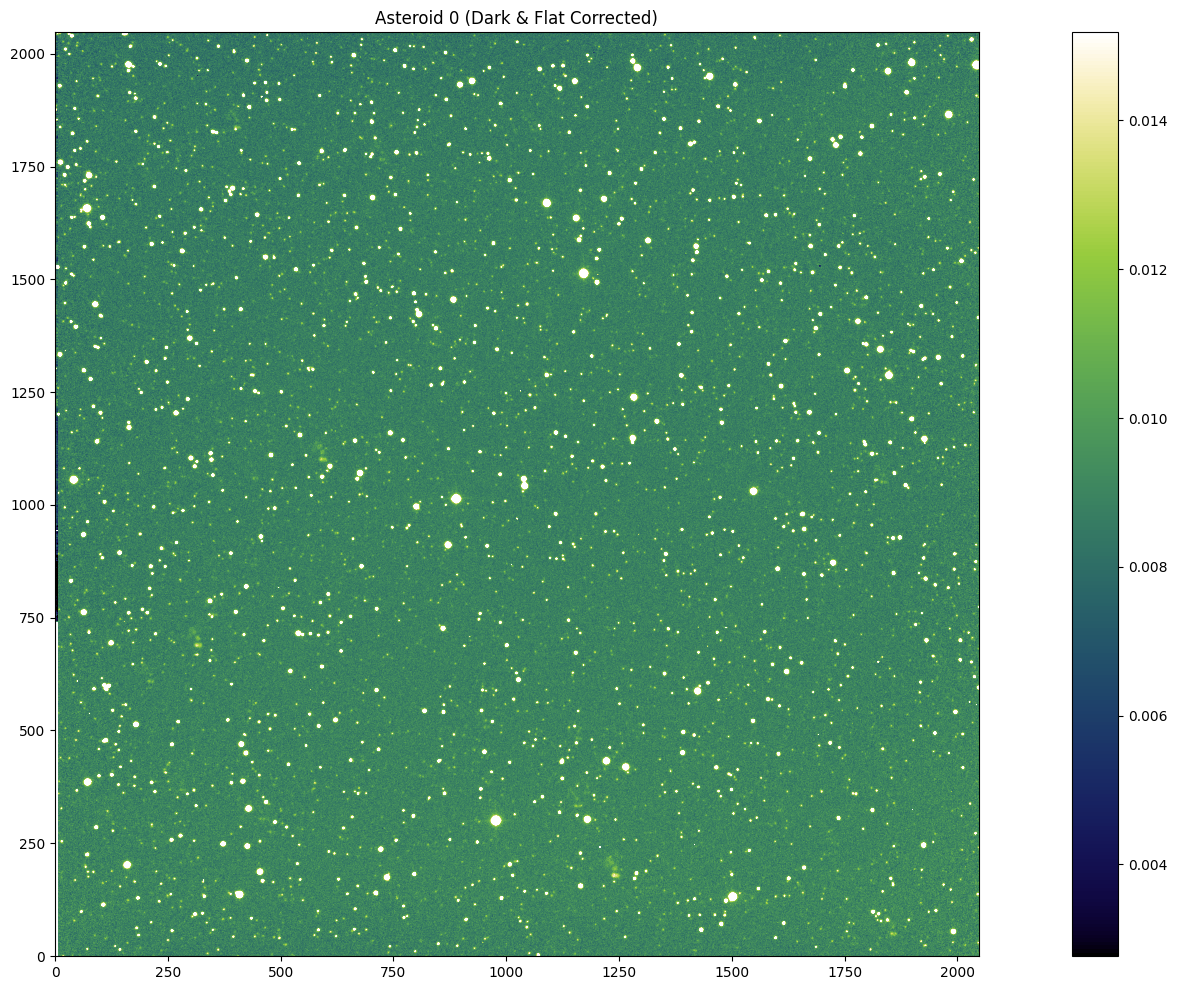

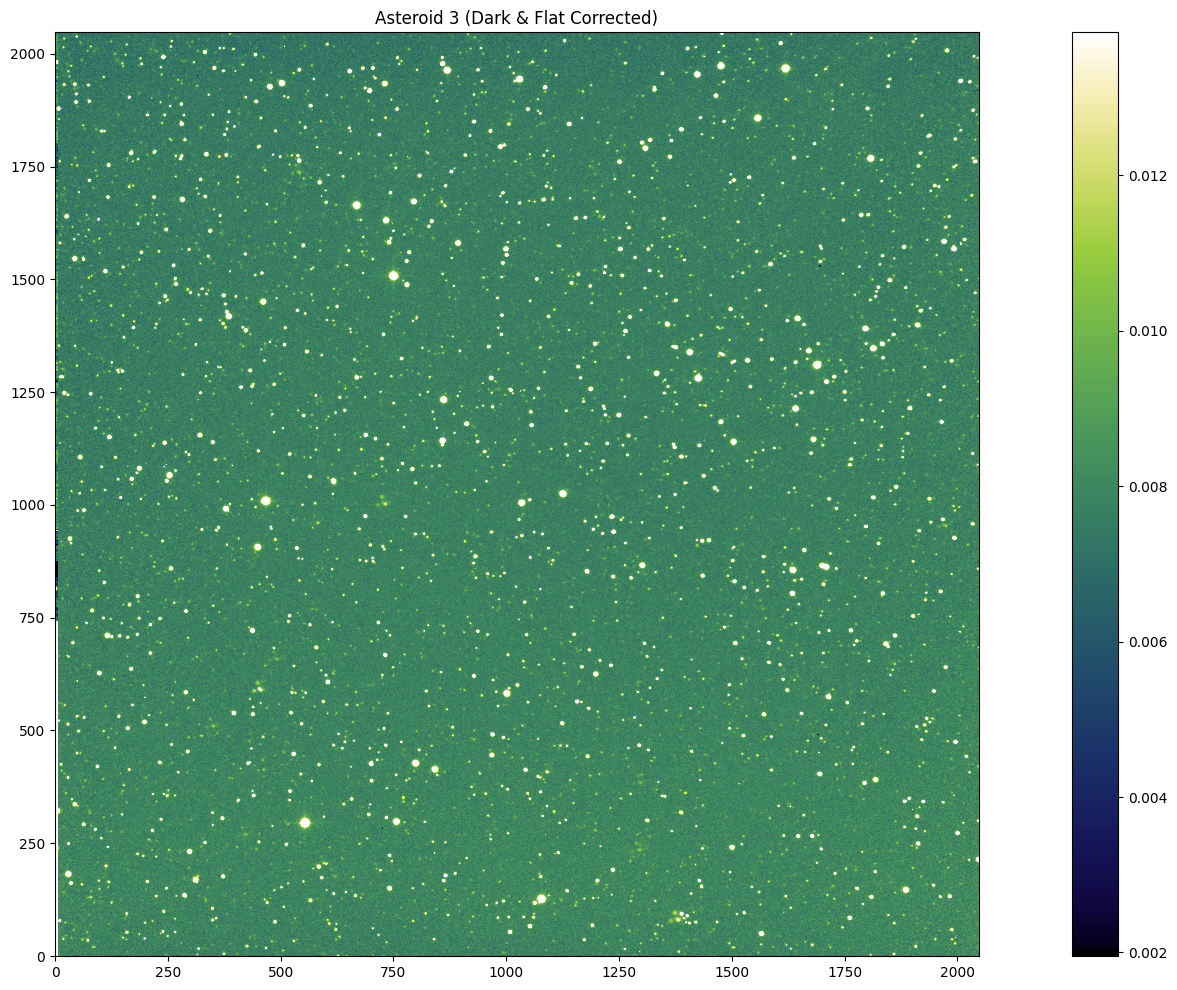

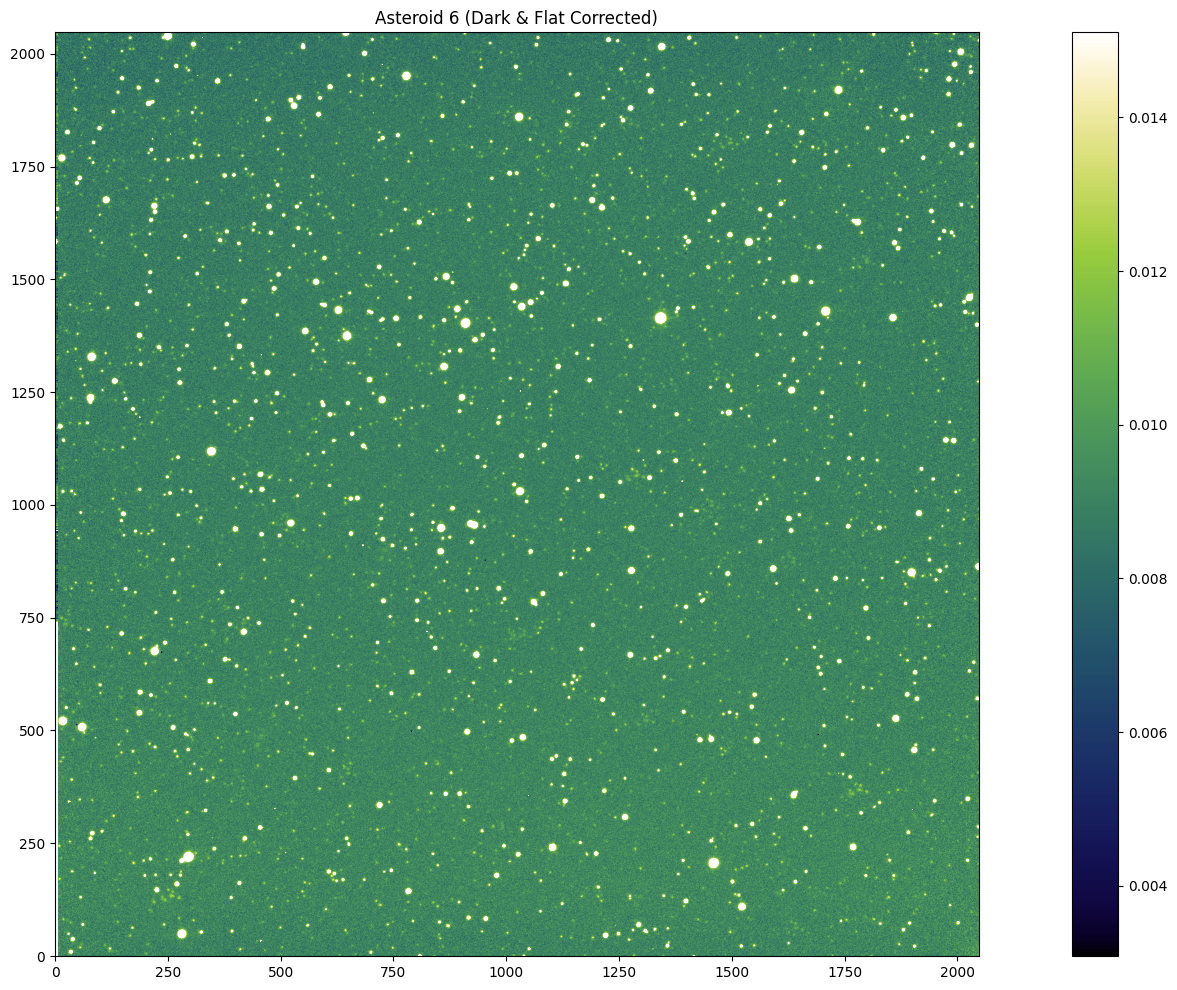

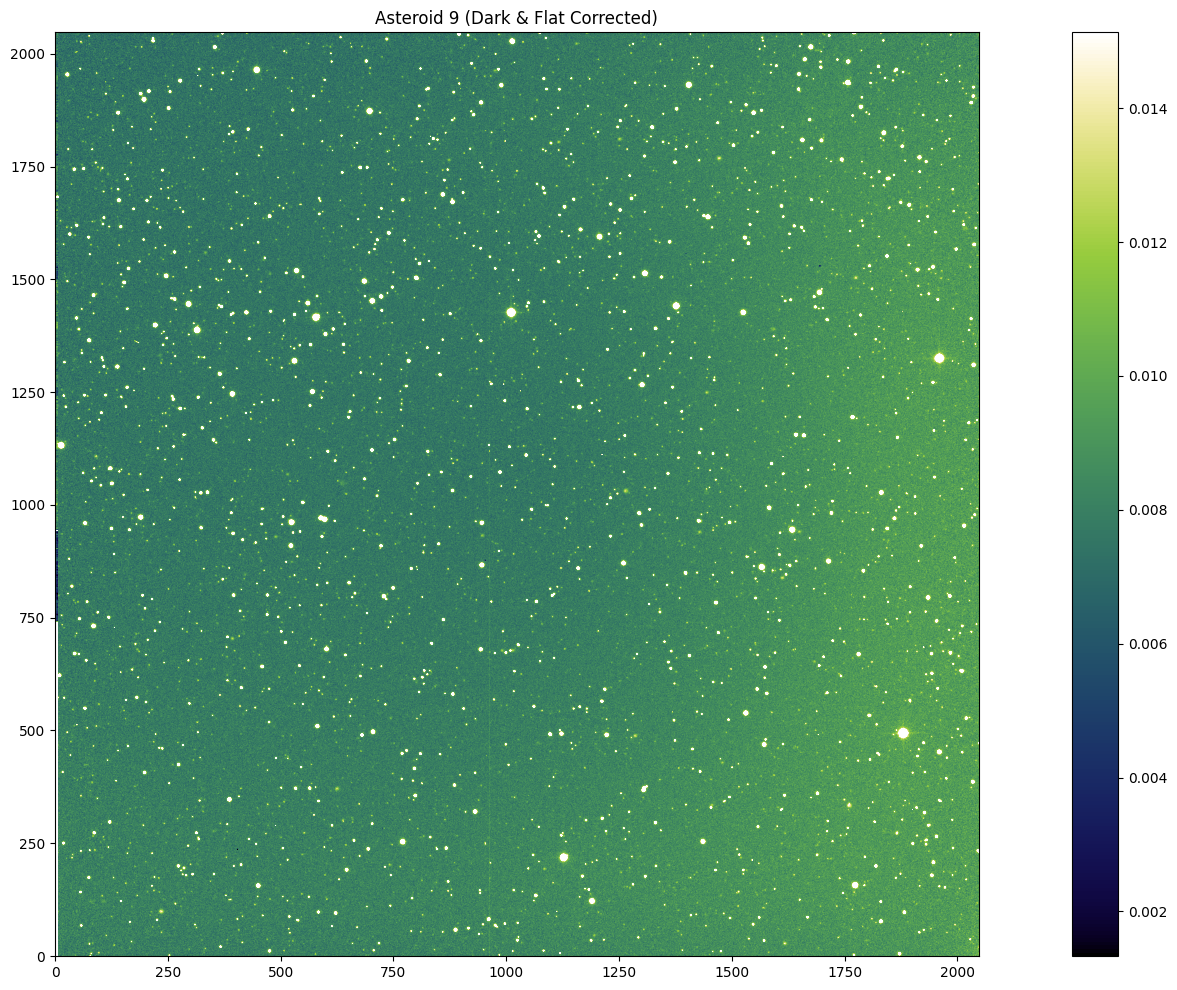

In [59]:

for i in [0,3,6,9]:
    view(science_imgs[i], "Asteroid {i} (Dark & Flat Corrected)".format(i=i), c="cma:lacerta")


**Crossmatching Stars**

Centroid Finding Algorithm

In [60]:
def star_gaussian(stars, image, threshold, plot=False, size=10, filter=False): 
    uncertainties = []   
    centroids_x_coords = []
    centroids_y_coords = []
    initial_cen_x = []
    initial_cen_y = []
    
    failed_fittings = 0
    size = size
    # 2d gaussian
    def gauss(xy, a, x0, y0, sigma_x, sigma_y, c):
        x, y = xy
        g = a*np.exp(-(x-x0)**2/(2*sigma_x**2) - (y-y0)**2/(2*sigma_y**2)) + c
        return g.ravel()

    for i in range(len(stars[0])):
        box = image[int(stars[1][i])-size:int(stars[1][i])+size, int(stars[0][i])-size:int(stars[0][i])+size]
        
        # Create coordinate matrices and flatten them for fitting
        xx, yy = np.meshgrid(np.arange(box.shape[1]), np.arange(box.shape[0])) 
        xx_flat = xx.ravel()
        yy_flat = yy.ravel()

        # Use centroid equation for initial guess
        x = np.sum(xx * box) / np.sum(box) 
        y = np.sum(yy * box) / np.sum(box) 

        # Fit Gaussian
        if len(yy_flat) != 0:            
            try:
                initial_guess = (1,x,y,size/2,size/2,0)
                popt, pcov = curve_fit(gauss, (xx_flat, yy_flat), box.ravel(), p0=initial_guess, nan_policy='omit')
                if filter:
                    if np.max(np.sqrt(np.diag(pcov))) < 0.0125:
                            
                        # get new centroid
                        centroid_x, centroid_y = popt[1], popt[2]
                        
                        # put the coords back in the original context of the image
                        x = stars[0][i] - size + x
                        y = stars[1][i] - size + y
                        
                        centroid_x = stars[0][i] - size + centroid_x
                        centroid_y = stars[1][i] - size + centroid_y
                        
                        # print(f"Initial Coordinate: {stars[0][i]}, {stars[1][i]}")
                        # print(f"Inital Centroid: {x}, {y}")
                        # print(f"Gaussian Centroid: {centroid_x}, {centroid_y}")
                        
                        # add centroids to list of coords
                        initial_cen_x.append(x)
                        initial_cen_y.append(y)
                        centroids_x_coords.append(centroid_x)
                        centroids_y_coords.append(centroid_y)
                        uncertainties.append(np.max(np.sqrt(np.diag(pcov))))
                                    # get new centroid
                else:
                    centroid_x, centroid_y = popt[1], popt[2]
                    # put the coords back in the original context of the image
                    x = stars[0][i] - size + x
                    y = stars[1][i] - size + y
                    
                    centroid_x = stars[0][i] - size + centroid_x
                    centroid_y = stars[1][i] - size + centroid_y
                    
                    # print(f"Initial Coordinate: {stars[0][i]}, {stars[1][i]}")
                    # print(f"Inital Centroid: {x}, {y}")
                    # print(f"Gaussian Centroid: {centroid_x}, {centroid_y}")
                    
                    # add centroids to list of coords
                    initial_cen_x.append(x)
                    initial_cen_y.append(y)
                    centroids_x_coords.append(centroid_x)
                    centroids_y_coords.append(centroid_y)
                    uncertainties.append(np.max(np.sqrt(np.diag(pcov))))
                
            except RuntimeError:
                failed_fittings += 1
    print(f"Fit {len(centroids_x_coords)} stars")
    print(f"Couldn't fit {failed_fittings} stars")
    return centroids_x_coords, centroids_y_coords, initial_cen_x, initial_cen_y, uncertainties
        

Applying to all stars

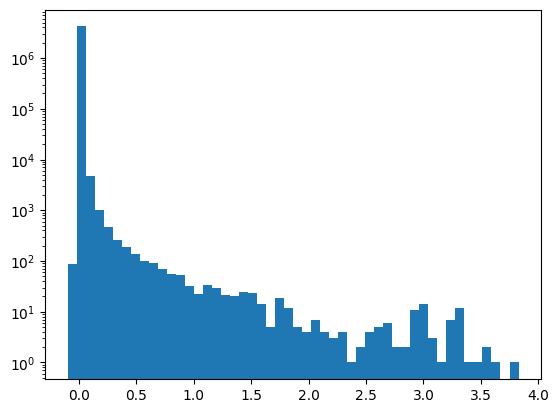

In [61]:
plt.hist(science_imgs[0].flatten(), bins=50)
plt.yscale('log')

In [62]:
threshold = 0.0150
stars_x = []
stars_y = []
# Find parts of img where intensity > threshold
binary_img = np.where(science_imgs[0] > threshold, 1, 0)

# Assign each star region a different integer
star_labels, num_stars = label(binary_img)
print(f"Found {num_stars} stars")

# Loop through each region and pick a single point to feed the centroider.
for i in range(1,num_stars+1):
    region_coords = np.where(star_labels == i)
    # Use middle point in each region
    middle_x = np.mean(region_coords[0]).astype(int)
    middle_y = np.mean(region_coords[1]).astype(int) 
    stars_x.append(middle_y)
    stars_y.append(middle_x)
    
size=8
centroid_x, centroid_y, initial_cen_x, initial_cen_y, std = star_gaussian([stars_x, stars_y], 
                                                                          science_imgs[0],threshold,size=size,
                                                                          filter=True)
centroid_catalog = pd.DataFrame({'centroid_x': centroid_x, 'centroid_y': centroid_y})
vmin, vmax = ZScaleInterval().get_limits(science_imgs[0])

# # View all centroids
# for centroid in range(len(centroid_x)):
#     fig = plt.figure(figsize=(12, 6))
#     plt.imshow(science_imgs[0], vmin=vmin, vmax=vmax, origin='lower', cmap='gray')
#     plt.scatter(stars_x,stars_y, marker='.', color='blue', label="Threshold detection", s=35)
#     plt.scatter(initial_cen_x[centroid],initial_cen_y[centroid], marker='x', color='green', label="Traditional Centroid", s=35)
#     plt.scatter(centroid_x[centroid],centroid_y[centroid], marker='x', color='red', label="Gaussian Centroid", s=35)
#     plt.xlim(centroid_x[centroid]-size-5,centroid_x[centroid]+size+5)
#     plt.ylim(centroid_y[centroid]-size-5,centroid_y[centroid]+size+5)
#     plt.legend(loc='best')
#     plt.show()



Found 2207 stars


/tmp/ipykernel_207715/3352928186.py:25: RuntimeWarning: invalid value encountered in scalar divide
  x = np.sum(xx * box) / np.sum(box)
/tmp/ipykernel_207715/3352928186.py:26: RuntimeWarning: invalid value encountered in scalar divide
  y = np.sum(yy * box) / np.sum(box)
/tmp/ipykernel_207715/3352928186.py:32: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(gauss, (xx_flat, yy_flat), box.ravel(), p0=initial_guess, nan_policy='omit')


Fit 153 stars
Couldn't fit 31 stars


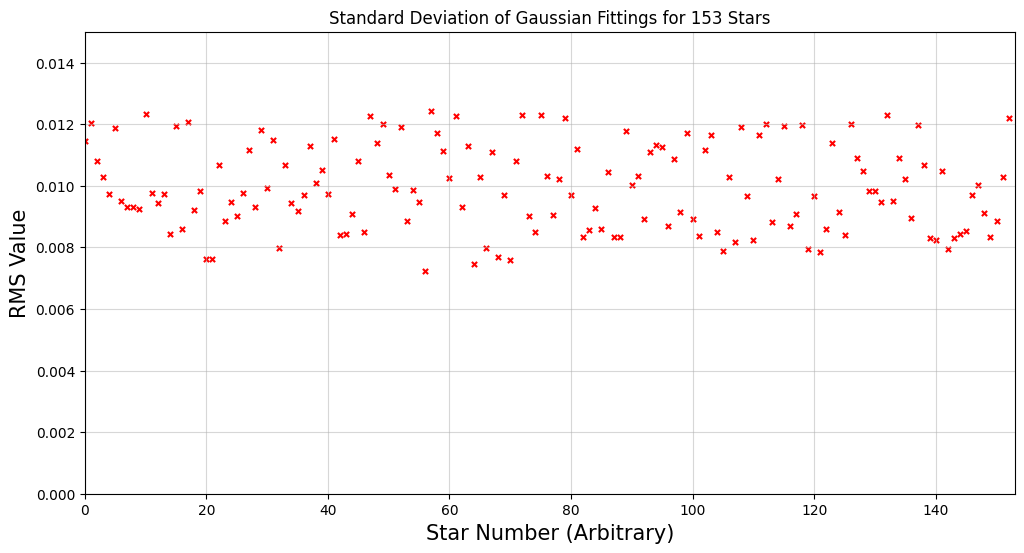

Average RMS Error of Gaussian Fittings:  0.00975348119206656


In [63]:
plt.figure(figsize=(12, 6))
plt.title(f"Standard Deviation of Gaussian Fittings for {len(std)} Stars")
plt.scatter(range(len(std)), std, s=14, color="red", marker="x")
plt.xlabel("Star Number (Arbitrary)", fontsize=15)
plt.ylabel("RMS Value", fontsize=15)
plt.grid(alpha=0.5)
plt.xlim(0,len(std))
plt.ylim(0,0.0150)
plt.show()
print("Average RMS Error of Gaussian Fittings: ", np.median(std))

Getting USNO coordinates

Converting USNO RA/DEC positions into pixel coordinates

81.031375 26.980694444444442


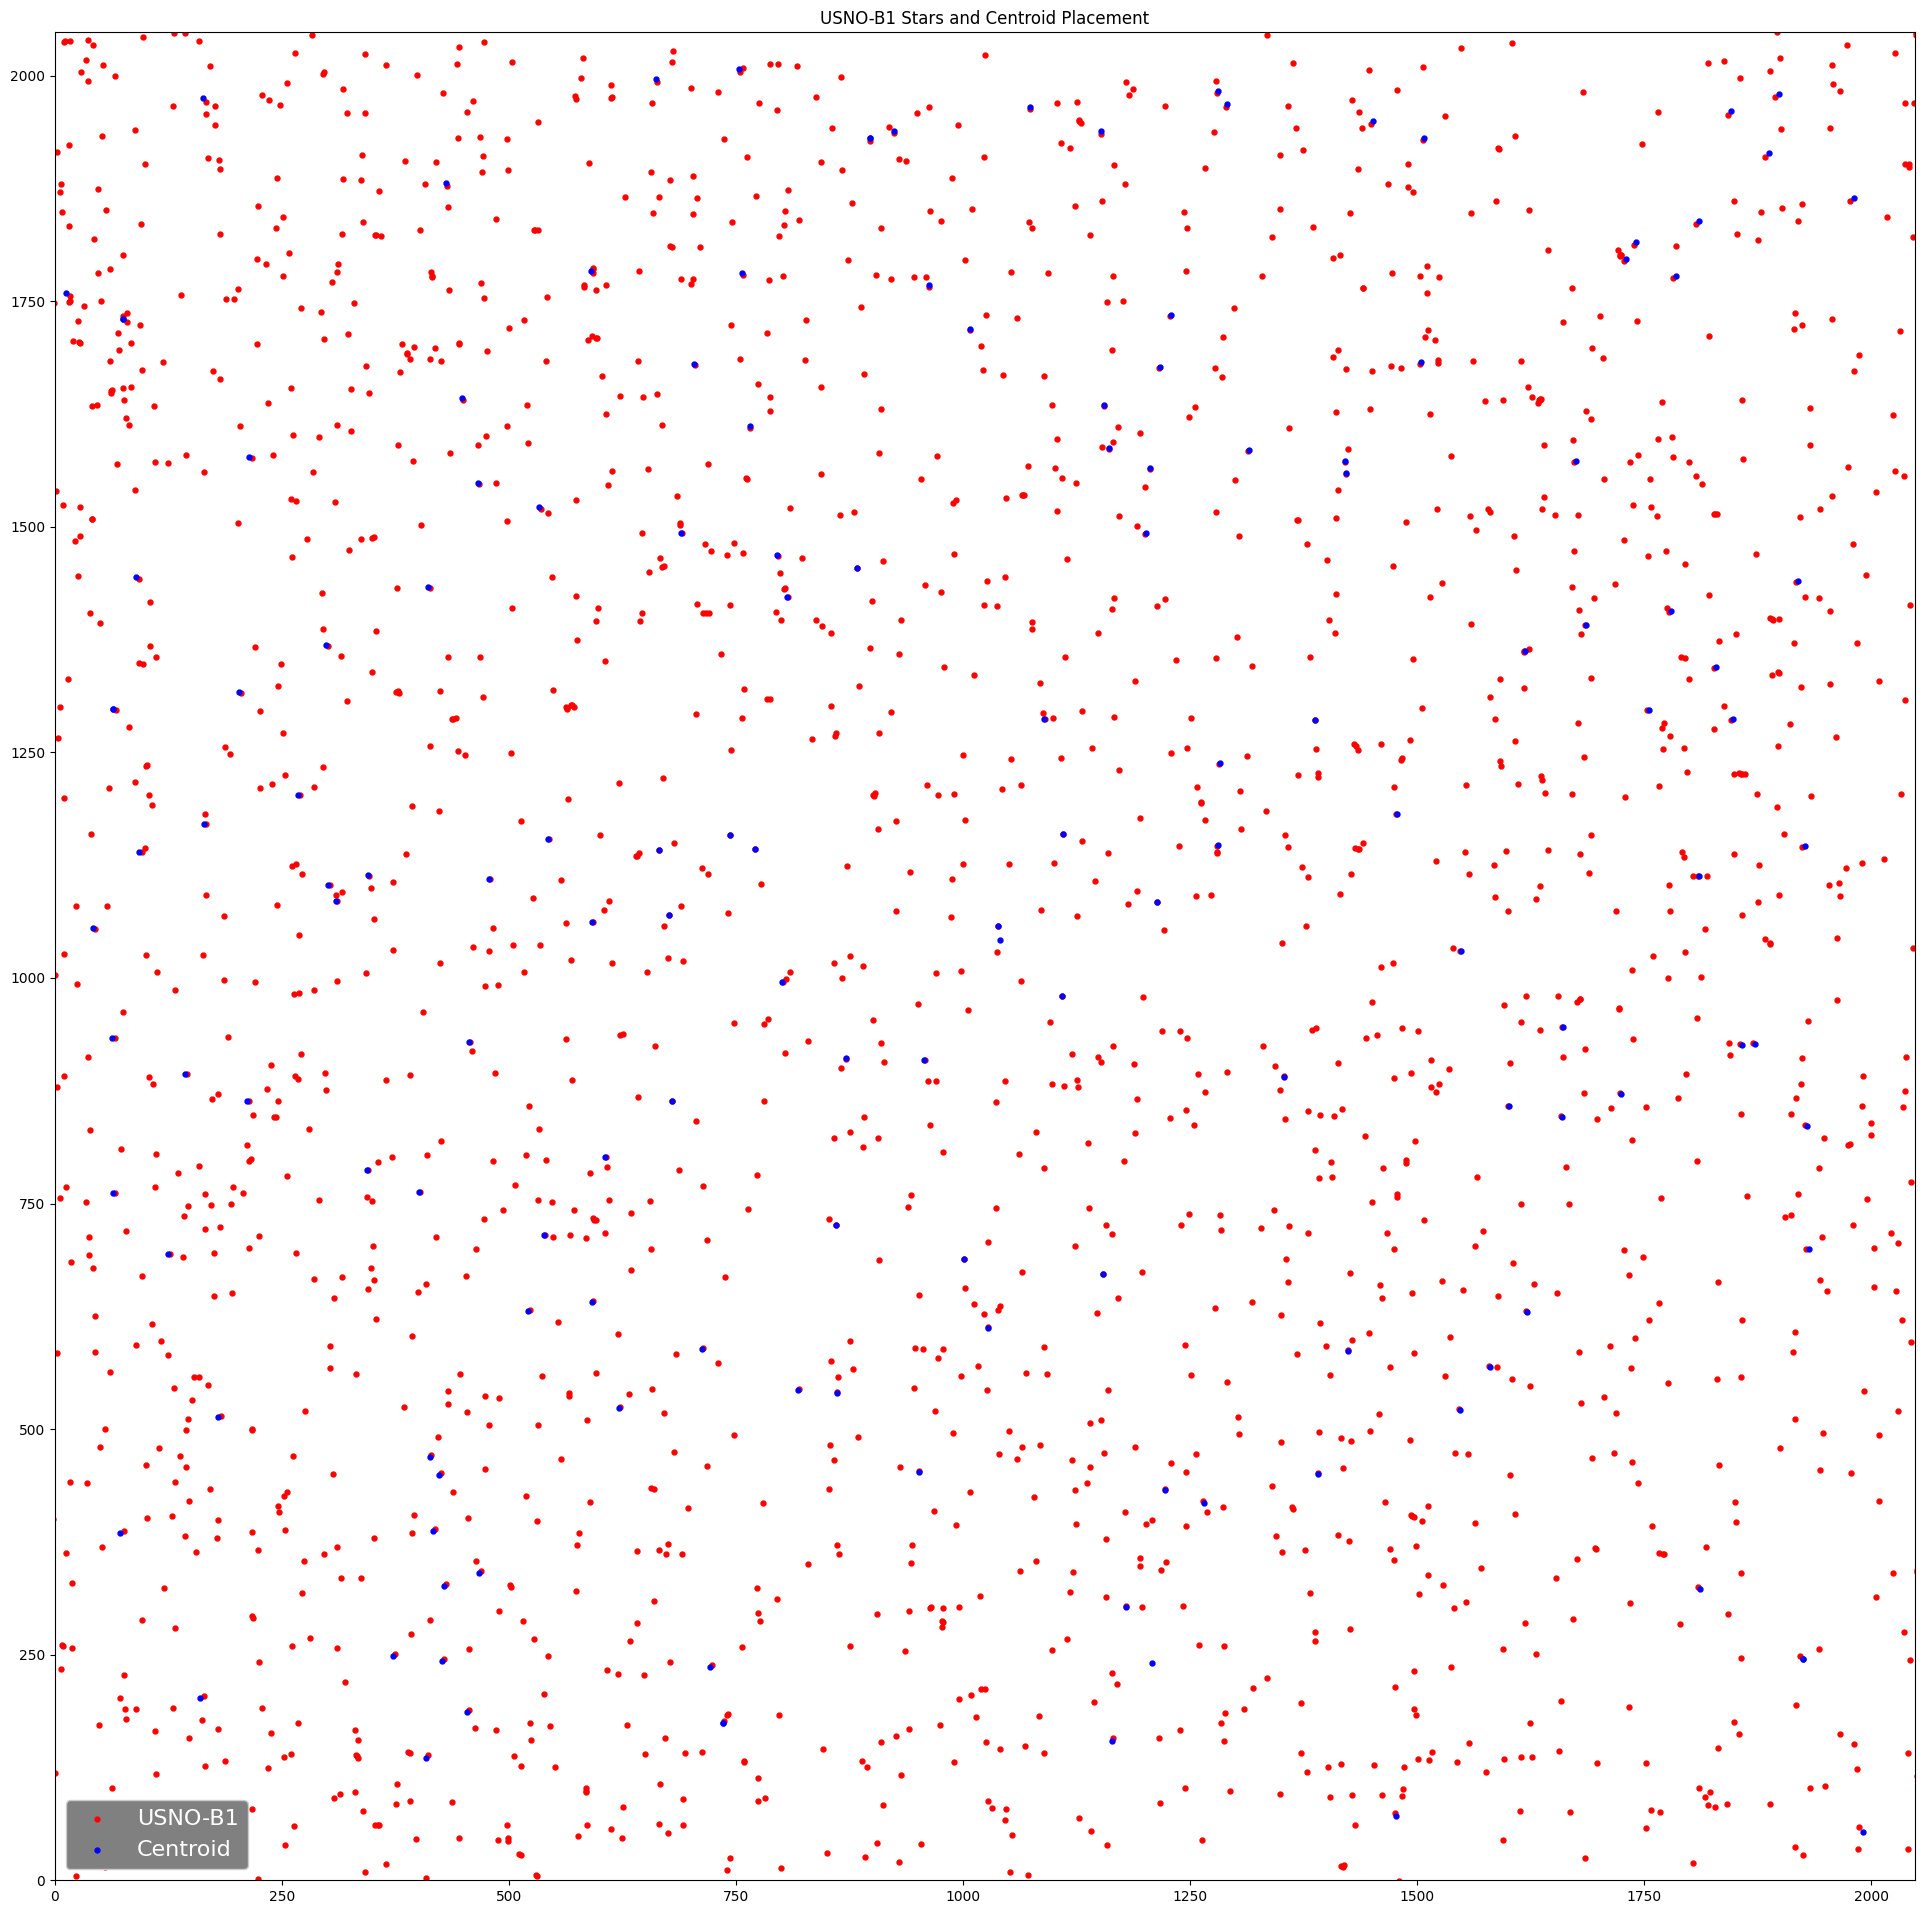

Num centroids 153
Num USNO 2198


In [64]:
# Get center of field and query USNO-B1
cof = coord.SkyCoord(header(astroids[0])['RA'], header(astroids[0])['DEC'], unit=(u.hourangle, u.deg), equinox='J2000')
print(cof.ra.deg, cof.dec.deg)
fov = 39*u.arcmin
Vizier.ROW_LIMIT = -1
usno = Vizier.query_region(cof, width=fov, catalog='USNO-B1')[0].to_pandas()

# plt.scatter(usno['RAJ2000'], usno['DEJ2000'], s=1, color='red')
# plt.xlabel('RA (deg)')
# plt.ylabel('Dec (deg)')
# plt.show()

mag_limit = 17
usno_reduced = usno[usno['R2mag'] < mag_limit].reset_index(drop=True)

# plt.scatter(usno_reduced['RAJ2000'], usno_reduced['DEJ2000'], s=2, color='red')
# plt.xlabel('RA (deg)')
# plt.ylabel('Dec (deg)')
# plt.show()

def initial_transform(usno_coords, focal_length, pixel_size, rotation, center_of_field, x_0, y_0):
    alpha = np.deg2rad(usno_coords[:,0])
    delta = np.deg2rad(usno_coords[:,1])
    alpha_0 = center_of_field.ra.rad
    delta_0 = center_of_field.dec.rad
    
    # Project to X and Y
    X = -((np.cos(delta)*np.sin(alpha - alpha_0))/((np.cos(delta_0))*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0)))
    Y = -((np.sin(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)-np.cos(delta_0)*np.sin(delta))/(np.cos(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0)))
    
    x_offset = x_0
    y_offset = y_0
    
    # Convert to pixels
    # x = focal_length*(X/pixel_size) + x_offset
    # y = focal_length*(Y/pixel_size) + y_offset
    
    x = (focal_length/pixel_size)*(X*np.cos(rotation) - Y*np.sin(rotation)) + x_offset
    y = (focal_length/pixel_size)*(X*np.sin(rotation) + Y*np.cos(rotation)) + y_offset
    return x,y

pixel_size = 0.009*2
image_shape = (2048, 2048) # after binning
#focal_length = 3454
focal_length = 3410
rotation = np.deg2rad(1.2)
x_offset = 1032
y_offset = 1042
usno_stars = np.column_stack((usno_reduced['RAJ2000'], usno_reduced['DEJ2000']))

approximate_x, approximate_y = initial_transform(usno_stars, focal_length, pixel_size, rotation, cof, x_offset, y_offset)
usno_reduced['approx_x'] = approximate_x
usno_reduced['approx_y'] = approximate_y

fig = plt.figure(figsize=(24, 24))
vmin, vmax = ZScaleInterval().get_limits(science_imgs[0])
#plt.imshow(science_imgs[0], cmap='cma:lacerta', origin='lower', vmin=vmin, vmax=vmax)

plt.scatter(usno_reduced['approx_x'], usno_reduced['approx_y'], marker='.', s=50, color='red', label='USNO-B1')
plt.title("USNO-B1 Stars and Centroid Placement")
plt.scatter(centroid_x, centroid_y, marker='.' , color ='blue', s=50, label='Centroid')
plt.xlim(0,2048)
plt.ylim(0,2048)
plt.legend(loc='lower left', fontsize = 16, labelcolor='white', facecolor='grey', framealpha = 1)
plt.show()

print("Num centroids" , len(centroid_x))
print("Num USNO" , len(usno_reduced['approx_x']))


In [65]:
# Returns nearest star 
def distance(centroid_catalog, catalog):    # Check distances between each centroid and all stars in catalog
    distances = cdist(centroid_catalog[['centroid_x', 'centroid_y']], catalog[['approx_x', 'approx_y']], metric='euclidean')
    nearest_star_indices = []
    nearest_star_distances = []
    # Find indexes of shortest distances for each centroid
    for i in range(len(distances)):
        nearest_star_indices.append(np.argmin(distances[i]))
        nearest_star_distances.append(np.min(distances[i]))
    return nearest_star_indices, nearest_star_distances

corresponding_usno, min_distance = distance(centroid_catalog, usno_reduced)
columns = ['USNO-B1.0','RAJ2000','DEJ2000','USNO_approx_x','USNO_approx_y','R2mag','pmRA','pmDE'] 
distance_threshold = 12
matched_stars = 0
total_centroids = len(centroid_catalog)
for i in range(len(centroid_catalog)):
    if min_distance[i] > distance_threshold:
        usno_reduced.loc[corresponding_usno[i], 'separation'] = np.nan
        usno_reduced.loc[corresponding_usno[i], 'x_centroid'] = centroid_catalog['centroid_x'][i]
        usno_reduced.loc[corresponding_usno[i], 'y_centroid'] = centroid_catalog['centroid_y'][i]
    else:
        usno_reduced.loc[corresponding_usno[i], 'separation'] = min_distance[i]
        usno_reduced.loc[corresponding_usno[i], 'x_centroid'] = centroid_catalog['centroid_x'][i]
        usno_reduced.loc[corresponding_usno[i], 'y_centroid'] = centroid_catalog['centroid_y'][i]
        matched_stars += 1
print(f"Matched {matched_stars} out of {total_centroids} centroids")
usno_reduced = usno_reduced[['USNO-B1.0','RAJ2000','DEJ2000','approx_x','approx_y','x_centroid','y_centroid','separation','R2mag','pmRA','pmDE']]
usno_reduced = usno_reduced.dropna()

Matched 151 out of 153 centroids


Plate Solving

Need to find T

Chi squared x: 45.397494066377234
Chi squared y: 75.41801550648465


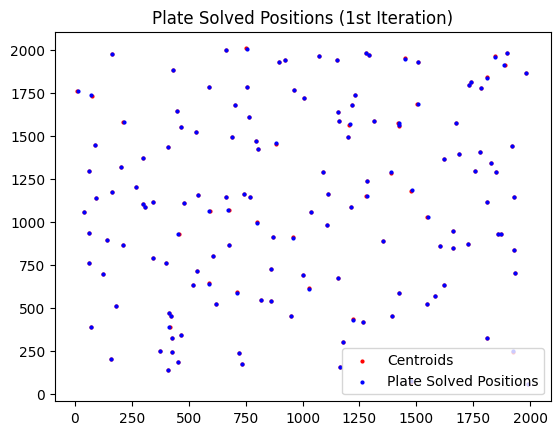

In [66]:
alpha = np.deg2rad(usno_reduced['RAJ2000'])
delta = np.deg2rad(usno_reduced['DEJ2000'])
alpha_0 = cof.ra.rad
delta_0 = cof.dec.rad
X = -(np.cos(delta)*np.sin(alpha - alpha_0))/((np.cos(delta_0))*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
Y = -(np.sin(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)-np.cos(delta_0)*np.sin(delta))/(np.cos(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))

# Solve for plate constants
f_p = focal_length/pixel_size
a_x = usno_reduced['x_centroid']
a_y = usno_reduced['y_centroid']
col1 = np.array(f_p*X)
col2 = np.array(f_p*Y)
col3 = np.ones_like(col1)
B = np.column_stack((col1, col2, col3))
c_x, uncertainty_x, _,_ = np.linalg.lstsq(B, a_x, rcond=None)
c_y, uncertainty_y,_,_ = np.linalg.lstsq(B, a_y, rcond=None)
T = np.array([[f_p*c_x[0], f_p*c_x[1], c_x[2]], [f_p*c_y[0], f_p*c_y[1], c_y[2]], [0, 0, 1]])

chi_squared_x = uncertainty_x[0] 
chi_squared_y = uncertainty_y[0] 

X_vec = np.array([X,Y,np.ones_like(X)])
x_lstsq = T[0][0]*X + T[0][1]*Y + T[0][2]
y_lstsq = T[1][0]*X + T[1][1]*Y + T[1][2]

print("Chi squared x:",chi_squared_x)
print("Chi squared y:",chi_squared_y)

usno_reduced['x_lstsq'] = x_lstsq
usno_reduced['y_lstsq'] = y_lstsq

plt.title("Plate Solved Positions (1st Iteration)")
plt.scatter(usno_reduced['x_centroid'], usno_reduced['y_centroid'], s=4, color='red', label='Centroids')
plt.scatter(usno_reduced['x_lstsq'], usno_reduced['y_lstsq'], s=4, color='blue', label='Plate Solved Positions')
plt.legend(loc='best')


In [67]:
usno_reduced.to_csv('usno_reduced.csv', index=False)

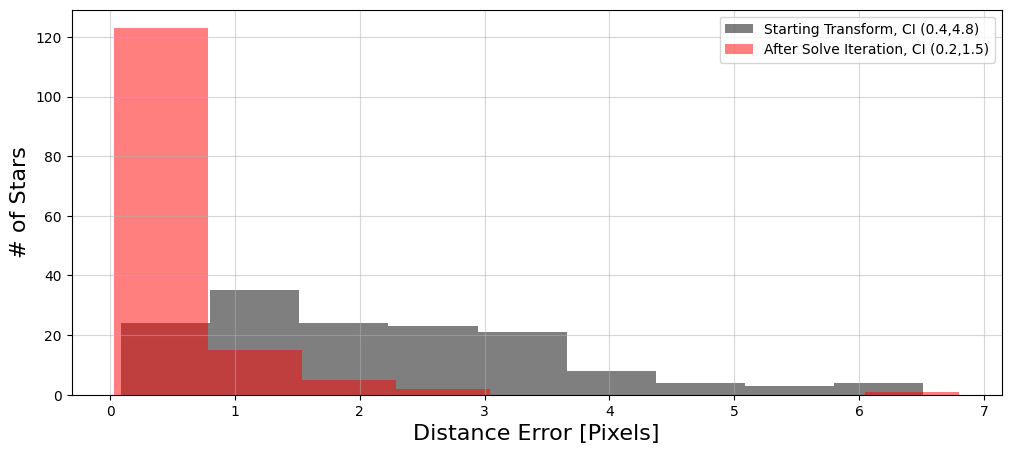

In [68]:
usno_x_approx = np.array(usno_reduced['approx_x'])
usno_y_approx = np.array(usno_reduced['approx_y'])
ccd_x = np.array(usno_reduced['x_centroid'])
ccd_y = np.array(usno_reduced['y_centroid'])
usno_x = np.array(usno_reduced['x_lstsq'])
usno_y = np.array(usno_reduced['y_lstsq'])

def distance(x1,y1,x2,y2):
    return np.sqrt((x1-x2)**2+(y1-y2)**2)

min_dists_before = np.empty_like(usno_x)
min_dists_after = np.empty_like(usno_x)
usno_x_approx = np.array(usno_reduced['approx_x'])

for i in range(usno_x.size):
    min_dists_before[i] = np.min(distance(usno_x_approx[i], usno_y_approx[i], ccd_x, ccd_y))
    min_dists_after[i] = np.min(distance(usno_x[i], usno_y[i], ccd_x, ccd_y))

CI_b = (np.percentile(min_dists_before,5), 
      np.percentile(min_dists_before,95))
CI_a = (np.percentile(min_dists_after,5), 
      np.percentile(min_dists_after,95))

fig = plt.figure(figsize=(12,5))
plt.hist(min_dists_before, 
         bins = "sturges", 
         color = 'k',
         alpha = 0.5, 
         label=f'Starting Transform, CI ({CI_b[0]:.1f},{CI_b[1]:.1f})')
plt.hist(min_dists_after, 
         bins = "sturges", 
         color = 'r',
         alpha = 0.5, 
         label =f'After Solve Iteration, CI ({CI_a[0]:.1f},{CI_a[1]:.1f})')
plt.grid(alpha=0.5)
plt.xlabel("Distance Error [Pixels]", size = 16)
plt.ylabel("# of Stars", size = 16)
plt.legend()
plt.show()

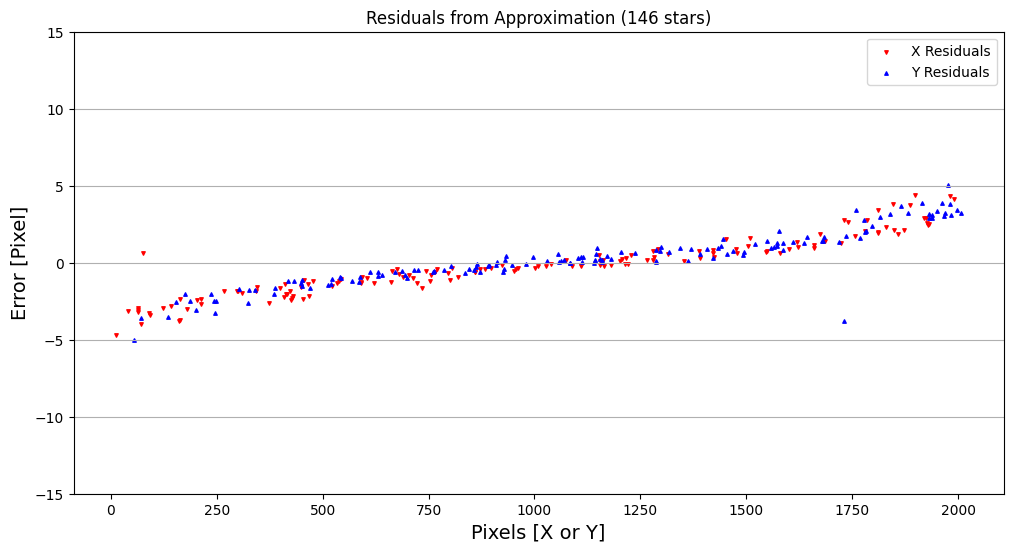

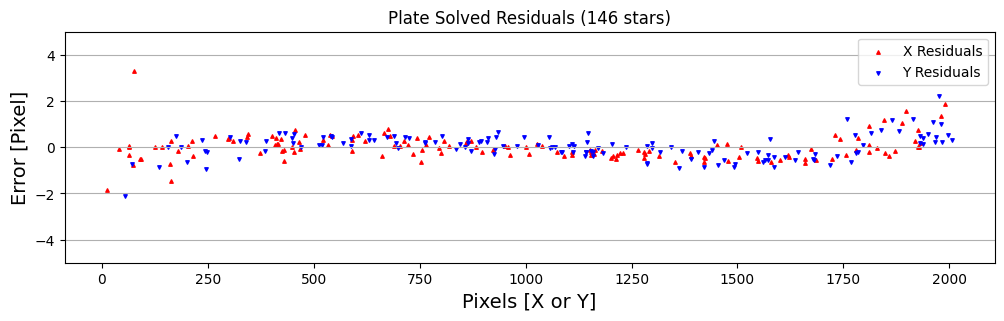

In [69]:
# Plot residuals
plt.figure(figsize=(12,6))
plt.title(f"Residuals from Approximation ({len(usno_reduced)} stars)")
plt.xlabel("Pixels [X or Y]", fontsize=14)
plt.ylabel("Error [Pixel]", fontsize = 14)
plt.scatter(usno_reduced['x_centroid'], usno_reduced['x_centroid'] - usno_reduced['approx_x'], s=6, color='red', label='X Residuals', marker="v")
plt.scatter(usno_reduced['y_centroid'], usno_reduced['y_centroid'] - usno_reduced['approx_y'], s=6, color='blue', label='Y Residuals', marker="^")
plt.legend(loc='best')
plt.ylim(-15,15)
plt.grid(axis='y')
plt.show()

plt.figure(figsize=(12,3))
plt.title(f"Plate Solved Residuals ({len(usno_reduced)} stars)")
plt.xlabel("Pixels [X or Y]", fontsize = 14)
plt.ylabel("Error [Pixel]", fontsize = 14)
plt.scatter(usno_reduced['x_centroid'], usno_reduced['x_centroid'] - usno_reduced['x_lstsq'], s=6, color='red', label='X Residuals', marker="^")
plt.scatter(usno_reduced['y_centroid'], usno_reduced['y_centroid'] - usno_reduced['y_lstsq'], s=6, color='blue', label='Y Residuals', marker="v")
plt.ylim(-5,5)
plt.grid(axis='y')
plt.legend(loc='best')

# Add residuals to dataframe
usno_reduced['x_residual'] = usno_reduced['x_centroid'] - usno_reduced['x_lstsq']
usno_reduced['y_residual'] = usno_reduced['y_centroid'] - usno_reduced['y_lstsq']

# Filter final stars by x and y residuals
residual_threshold = 1 # pixels
final_stars = usno_reduced[(np.abs(usno_reduced['x_residual']) < residual_threshold) & (np.abs(usno_reduced['y_residual']) < residual_threshold)]

Chi squared x: 17.401205513912966
Chi squared y: 22.919477447854923
Total RMSE Fitting: 0.38221647141495374


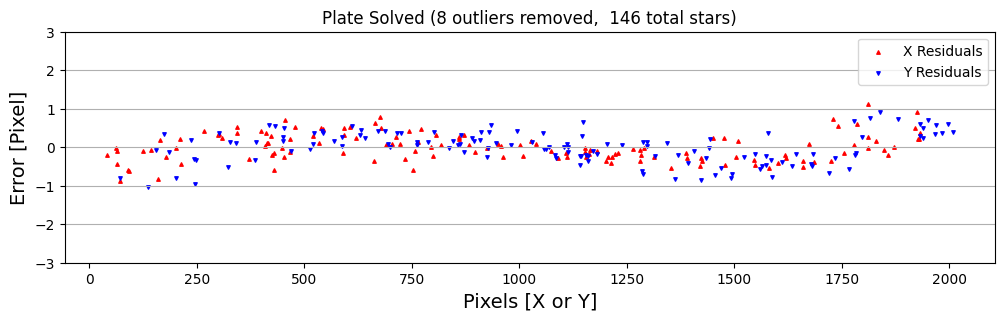

In [89]:
# Calculate a final T with outliers removed
alpha = np.deg2rad(final_stars['RAJ2000'])
delta = np.deg2rad(final_stars['DEJ2000'])
alpha_0 = cof.ra.rad
delta_0 = cof.dec.rad
X = -(np.cos(delta)*np.sin(alpha - alpha_0))/((np.cos(delta_0))*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
Y = -(np.sin(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)-np.cos(delta_0)*np.sin(delta))/(np.cos(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))

# Solve for plate constants
f_p = focal_length/pixel_size
a_x = final_stars['x_centroid']
a_y = final_stars['y_centroid']
col1 = np.array(f_p*X)
col2 = np.array(f_p*Y)
col3 = np.ones_like(col1)
B = np.column_stack((col1, col2, col3))
c_x = np.linalg.lstsq(B, a_x, rcond=None)[0]
c_y = np.linalg.lstsq(B, a_y, rcond=None)[0]
T = np.array([[f_p*c_x[0], f_p*c_x[1], c_x[2]], [f_p*c_y[0], f_p*c_y[1], c_y[2]], [0, 0, 1]])

chi_squared_x = (a_x-B@c_x).T@(a_x-B@c_x)
chi_squared_y = (a_y-B@c_y).T@(a_y-B@c_y)
rmse_fit = np.sqrt((chi_squared_x + chi_squared_y)/(len(a_x) + len(a_y)))

print("Chi squared x:",chi_squared_x)
print("Chi squared y:",chi_squared_y)
print("Total RMSE Fitting:",rmse_fit)


X_vec = np.array([X,Y,np.ones_like(X)])
x_lstsq = T[0][0]*X + T[0][1]*Y + T[0][2]
y_lstsq = T[1][0]*X + T[1][1]*Y + T[1][2]

final_stars.loc[:, 'x_lstsq'] = x_lstsq
final_stars.loc[:, 'y_lstsq'] = y_lstsq

plt.figure(figsize=(12,3))
plt.title(f"Plate Solved ({len(usno_reduced) - len(final_stars)} outliers removed,  {len(usno_reduced)} total stars)")
plt.xlabel("Pixels [X or Y]", fontsize = 14)
plt.ylabel("Error [Pixel]", fontsize = 14)
plt.scatter(final_stars['x_centroid'], final_stars['x_centroid'] - final_stars['x_lstsq'], s=6, color='red', label='X Residuals', marker="^")
plt.scatter(final_stars['y_centroid'], final_stars['y_centroid'] - final_stars['y_lstsq'], s=6, color='blue', label='Y Residuals', marker="v")
plt.ylim(-3,3)
plt.grid(axis='y')
plt.legend(loc='best')

Now to deal with proserpina. First converting approximate locations from tutorial to pixel space.

In [90]:
def RADec_pixel(coordinate, center_field):
    alpha = coordinate.ra.rad
    delta = coordinate.dec.rad  
    alpha_0 = center_field.ra.rad
    delta_0 = center_field.dec.rad
    X = -(np.cos(delta)*np.sin(alpha - alpha_0))/((np.cos(delta_0))*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
    Y = -(np.sin(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)-np.cos(delta_0)*np.sin(delta))/(np.cos(delta_0)*np.cos(delta)*np.cos(alpha-alpha_0)+np.sin(delta)*np.sin(delta_0))
    x = T[0][0]*X + T[0][1]*Y + T[0][2]
    y = T[1][0]*X + T[1][1]*Y + T[1][2]
    return x, y

# emphemeris = [("81.02", "26.98"), 
#               ("80.88" ,"26.967"), 
#               ("80.62", "26.94"), 
#               ("80.31", "26.907")]


emphemeris = [("05 24 06.75", "26 58 48.3"), 
              ("05 23 33.06" ,"26 58 03.9"), 
              ("05 22 30.16", "26 56 32.4"), 
              ("05 21 14.29", "26 54 24.8")]

coord1 = coord.SkyCoord(emphemeris[0][0], emphemeris[0][1], unit=(u.hourangle, u.deg), equinox='J2000')
coord2 = coord.SkyCoord(emphemeris[1][0], emphemeris[1][1], unit=(u.hourangle, u.deg), equinox='J2000')
coord3 = coord.SkyCoord(emphemeris[2][0], emphemeris[2][1], unit=(u.hourangle, u.deg), equinox='J2000')
coord4 = coord.SkyCoord(emphemeris[3][0], emphemeris[3][1], unit=(u.hourangle, u.deg), equinox='J2000')

# Convert coordinates to pixel space
coord1_cof = coord.SkyCoord(header(astroids[0])['RA'], header(astroids[0])['DEC'], unit=(u.hourangle, u.deg), equinox='J2000')
coord2_cof = coord.SkyCoord(header(astroids[3])['RA'], header(astroids[1])['DEC'], unit=(u.hourangle, u.deg), equinox='J2000')
coord3_cof = coord.SkyCoord(header(astroids[6])['RA'], header(astroids[2])['DEC'], unit=(u.hourangle, u.deg), equinox='J2000')
coord4_cof = coord.SkyCoord(header(astroids[9])['RA'], header(astroids[3])['DEC'], unit=(u.hourangle, u.deg), equinox='J2000')

coord1x, coord1y = RADec_pixel(coord1, coord1_cof)
coord2x, coord2y = RADec_pixel(coord2, coord2_cof)
coord3x, coord3y = RADec_pixel(coord3, coord3_cof)
coord4x, coord4y = RADec_pixel(coord4, coord4_cof)

# Day 1
d1t1 = header(asteroid1[0])['DATE-OBS']
d1t2 = header(asteroid1[1])['DATE-OBS']
d1t3 = header(asteroid1[2])['DATE-OBS']

# Day 2
d2t1 = header(asteroid2[0])['DATE-OBS']
d2t2 = header(asteroid2[1])['DATE-OBS']
d2t3 = header(asteroid2[2])['DATE-OBS']

# Day 3
d3t1 = header(asteroid3[0])['DATE-OBS']
d3t2 = header(asteroid3[1])['DATE-OBS']
d3t3 = header(asteroid3[2])['DATE-OBS']

# Day 4 
d4t1 = header(asteroid4[0])['DATE-OBS']
d4t2 = header(asteroid4[1])['DATE-OBS']
d4t3 = header(asteroid4[2])['DATE-OBS']

timestamps = [d1t1, d1t2, d1t3, d2t1, d2t2, d2t3, d3t1, d3t2, d3t3]

Fit 1 stars
Couldn't fit 0 stars
Fit 1 stars
Couldn't fit 0 stars
Fit 1 stars
Couldn't fit 0 stars
Fit 1 stars
Couldn't fit 0 stars
Day 1 Uncertainty:  [0.006867449024880587]
Day 2 Uncertainty:  [0.010616612893319789]
Day 3 Uncertainty:  [0.011282870911420223]
Day 4 Uncertainty:  [0.0131049921897337]
Day 1 approx. RA DEC: (81.028125, 26.980083333333333)
Day 2 approx. RA DEC: (80.88775, 26.96775)
Day 3 approx. RA DEC: (80.62566666666665, 26.942333333333334)
Day 4 approx. RA DEC: (80.30954166666665, 26.906888888888886)
Day 1 (Px): (1041.4480206318076, 1040.22689142797)
Day 2 (Px): (1044.9979317381142, 999.3956724794352)
Day 3 (Px): (1059.4155472962077, 915.398738619441)
Day 4 (Px): (1646.3050782019718, 851.1088319120397)
Day 1 centroid: (1041.1258343386007, 1041.8098305674816)
Day 2 centroid: (1035.4965293244804, 1004.2830800840802)
Day 3 centroid: (1030.992908217247, 1029.8225685202533)
Day 4 centroid: (1633.8874747185926, 944.4583915297566)


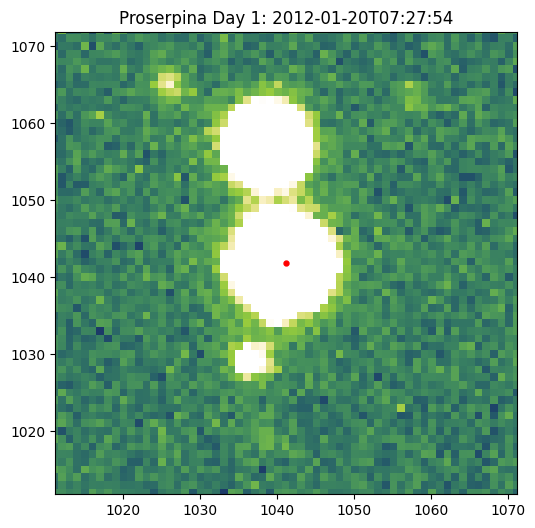

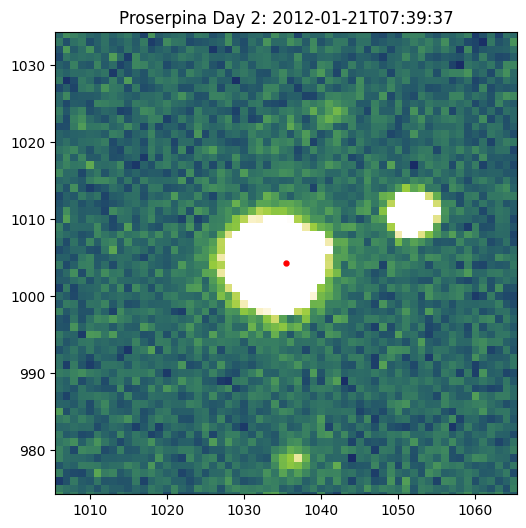

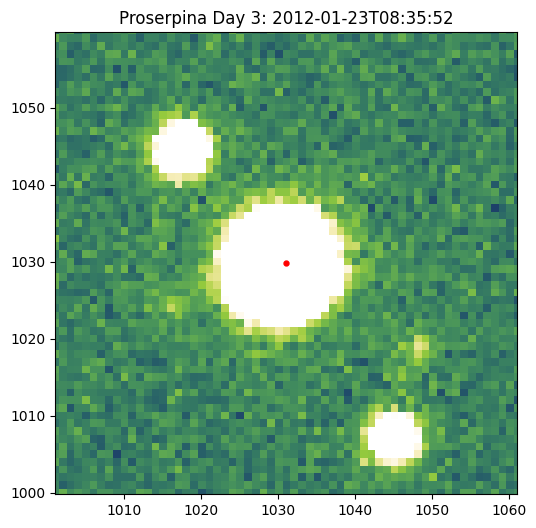

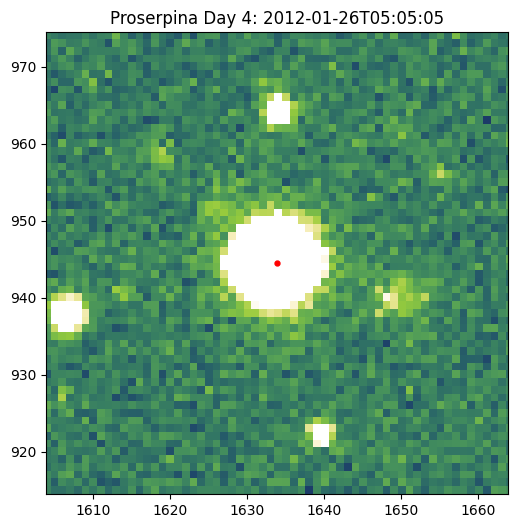

In [91]:
# Centroiding proserpina
box = 10
x1, y1, _, _, d1_uncertainty = star_gaussian([[coord1x],[coord1y-2]], science_imgs[0], plot=True, size=box, threshold = 1, filter = False)
x2, y2, _, _, d2_uncertainty = star_gaussian([[coord2x - 10],[coord2y+5]], science_imgs[3], plot=True, size=box, threshold = 1, filter = False)
x3, y3, _, _, d3_uncertainty = star_gaussian([[coord3x -30],[coord3y+115]], science_imgs[6], plot=True, size=box, threshold = 1, filter=False)
x4, y4, _, _, d4_uncertainty = star_gaussian([[coord4x -12],[coord4y + 92]], science_imgs[9], plot=True, size=box, threshold = 1, filter=False)

x1, y1 = x1[0], y1[0]
x2, y2 = x2[0], y2[0]
x3, y3 = x3[0], y3[0]
x4, y4 = x4[0], y4[0]

print("Day 1 Uncertainty: ", d1_uncertainty)
print("Day 2 Uncertainty: ", d2_uncertainty)
print("Day 3 Uncertainty: ", d3_uncertainty)
print("Day 4 Uncertainty: ", d4_uncertainty)

# x1, y1 = coord1x, coord1y
# x2, y2 = coord2x-10, coord2y+5
# x3, y3 = coord3x - 30, coord3y + 115
# x4, y4 = coord4x-12, coord4y + 92

print(f"Day 1 approx. RA DEC: {coord1.ra.deg, coord1.dec.deg}")
print(f"Day 2 approx. RA DEC: {coord2.ra.deg, coord2.dec.deg}")
print(f"Day 3 approx. RA DEC: {coord3.ra.deg, coord3.dec.deg}")
print(f"Day 4 approx. RA DEC: {coord4.ra.deg, coord4.dec.deg}")

print(f"Day 1 (Px): {coord1x, coord1y}")
print(f"Day 2 (Px): {coord2x, coord2y}")
print(f"Day 3 (Px): {coord3x, coord3y}")
print(f"Day 4 (Px): {coord4x, coord4y}")

x_proserpina = np.array([[x1, x2, x3, x4], [y1, y2, y3, y4], np.ones_like([x1, x2, x3, x4])])

print(f'Day 1 centroid: {x1, y1}')
print(f'Day 2 centroid: {x2, y2}')
print(f'Day 3 centroid: {x3, y3}')
print(f'Day 4 centroid: {x4, y4}')

vmin, max = ZScaleInterval().get_limits(science_imgs[0])

# Day 1 
fig = plt.figure(figsize=(12, 6))
plt.title(f"Proserpina Day 1: {d1t1}")
plt.imshow(science_imgs[0], cmap='cma:lacerta', vmin=vmin, vmax=max)
plt.scatter(x1, y1, marker='.', color='red', s=50, label='Centroid 1')
plt.xlim(x1-box-20, x1+box+20)
plt.ylim(y1-box-20, y1+box+20)
plt.show()

# Day 2
fig = plt.figure(figsize=(12, 6))
plt.title(f"Proserpina Day 2: {d2t1}")
plt.imshow(science_imgs[3], cmap='cma:lacerta', origin='lower', vmin=vmin, vmax=max)
plt.scatter(x2, y2, marker='.', color='red', s=50, label='Centroid 2')
plt.xlim(x2-box-20, x2+box+20)
plt.ylim(y2-box-20, y2+box+20)
plt.show()

# Day 3
fig = plt.figure(figsize=(12, 6))
plt.title(f"Proserpina Day 3: {d3t1}")
plt.imshow(science_imgs[6], cmap='cma:lacerta', origin='lower', vmin=vmin, vmax=max)
plt.scatter(x3, y3, marker='.', color='red', s=50, label='Centroid 3')
plt.xlim(x3-box-20, x3+box+20)
plt.ylim(y3-box-20, y3+box+20)
plt.show()

# Day 4
fig = plt.figure(figsize=(12, 6))
plt.title(f"Proserpina Day 4: {d4t1}")
plt.imshow(science_imgs[9], cmap='cma:lacerta', origin='lower', vmin=vmin, vmax=max)
plt.scatter(x4, y4, marker='.', color='red', s=50, label='Centroid 4')
plt.xlim(x4-box-20, x4+box+20)
plt.ylim(y4-box-20, y4+box+20)
plt.show()


[[ 4.90253655e-05  1.53396901e-05 -5.59858269e-06  3.15804765e-03]
 [-2.29995767e-06 -1.99160763e-04 -6.42694759e-05 -5.79613870e-04]
 [ 1.00000000e+00  1.00000000e+00  1.00000000e+00  1.00000000e+00]]
Day 1 approx RA DEC (deg): , (81.028125, 26.980083333333333)
Day 1 Calculated RA DEC (deg): (81.02822299026867, 26.980562631523192)
Day 2 approx RA DEC (deg): , (80.88775, 26.96775)
Day 2 Calculated RA DEC (deg): (80.89093052394848, 26.96928336997808)
Day 3 approx RA DEC (deg): , (80.62566666666665, 26.942333333333334)
Day 3 Calculated RA DEC (deg): (80.63448494082361, 26.977012074273308)
Day 4 approx RA DEC (deg): , (80.30954166666665, 26.906888888888886)
Day 4 Calculated RA DEC (deg): (80.31304074382788, 26.935117627012062)


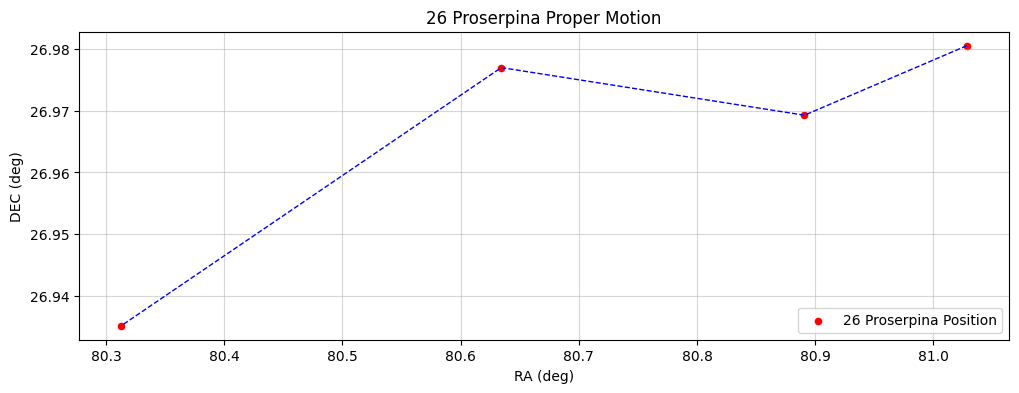

In [85]:
# Convert to RA and DEC
X_vec_proserpina = np.linalg.inv(T) @ x_proserpina
print(X_vec_proserpina)

X_proserpina = X_vec_proserpina[0]
Y_proserpina = X_vec_proserpina[1]

ra1_proserpina = np.arctan((-X_proserpina[0])/(np.cos(coord1_cof.dec.rad) - Y_proserpina[0]*np.sin(coord1_cof.dec.rad))) + coord1_cof.ra.rad
dec1_proserpina = np.arcsin((np.sin(coord1_cof.dec.rad)+Y_proserpina[0]*np.cos(coord1_cof.dec.rad))/(np.sqrt(1+X_proserpina[0]**2 + Y_proserpina[0]**2)))

ra2_proserpina = np.arctan((-X_proserpina[1])/(np.cos(coord2_cof.dec.rad) - Y_proserpina[1]*np.sin(coord2_cof.dec.rad))) + coord2_cof.ra.rad
dec2_proserpina = np.arcsin((np.sin(coord2_cof.dec.rad) + Y_proserpina[1]*np.cos(coord2_cof.dec.rad))/(np.sqrt(1+X_proserpina[1]**2 + Y_proserpina[1]**2)))

ra3_proserpina = np.arctan((-X_proserpina[2])/(np.cos(coord3_cof.dec.rad) - Y_proserpina[2]*np.sin(coord3_cof.dec.rad))) + coord3_cof.ra.rad
dec3_proserpina = np.arcsin((np.sin(coord3_cof.dec.rad) + Y_proserpina[2]*np.cos(coord3_cof.dec.rad))/(np.sqrt(1+X_proserpina[2]**2 + Y_proserpina[2]**2)))

ra4_proserpina = np.arctan((-X_proserpina[3])/(np.cos(coord4_cof.dec.rad) - Y_proserpina[3]*np.sin(coord4_cof.dec.rad))) + coord4_cof.ra.rad
dec4_proserpina = np.arcsin((np.sin(coord4_cof.dec.rad) + Y_proserpina[3]*np.cos(coord4_cof.dec.rad))/(np.sqrt(1+X_proserpina[3]**2 + Y_proserpina[3]**2)))

proserpina1 = coord.SkyCoord(ra1_proserpina, dec1_proserpina, unit=(u.rad, u.rad), equinox='J2000')
proserpina2 = coord.SkyCoord(ra2_proserpina, dec2_proserpina, unit=(u.rad, u.rad), equinox='J2000')
proserpina3 = coord.SkyCoord(ra3_proserpina, dec3_proserpina, unit=(u.rad, u.rad), equinox='J2000')
proserpina4 = coord.SkyCoord(ra4_proserpina, dec4_proserpina, unit=(u.rad, u.rad), equinox='J2000')

proserpina_calculated_ra = [proserpina1.ra.deg, proserpina2.ra.deg, proserpina3.ra.deg, proserpina4.ra.deg]
proserpina_calculated_dec = [proserpina1.dec.deg, proserpina2.dec.deg, proserpina3.dec.deg, proserpina4.dec.deg]

print(f"Day 1 approx RA DEC (deg): , {coord1.ra.deg, coord1.dec.deg}")
print(f"Day 1 Calculated RA DEC (deg): {proserpina1.ra.deg, proserpina1.dec.deg}")
print(f"Day 2 approx RA DEC (deg): , {coord2.ra.deg, coord2.dec.deg}")
print(f"Day 2 Calculated RA DEC (deg): {proserpina2.ra.deg, proserpina2.dec.deg}")
print(f"Day 3 approx RA DEC (deg): , {coord3.ra.deg, coord3.dec.deg}")
print(f"Day 3 Calculated RA DEC (deg): {proserpina3.ra.deg, proserpina3.dec.deg}")
print(f"Day 4 approx RA DEC (deg): , {coord4.ra.deg, coord4.dec.deg}")
print(f"Day 4 Calculated RA DEC (deg): {proserpina4.ra.deg, proserpina4.dec.deg}")

fig = plt.figure(figsize=(12, 4))
plt.title("26 Proserpina Proper Motion")
plt.xlabel("RA (deg)")
plt.ylabel("DEC (deg)")
plt.scatter(proserpina_calculated_ra, proserpina_calculated_dec, s=20, color='red', label="26 Proserpina Position")
plt.plot(proserpina_calculated_ra, proserpina_calculated_dec, color='blue', linestyle='--', linewidth=1)
plt.grid(alpha=0.5)
plt.legend(loc="lower right")
plt.show()


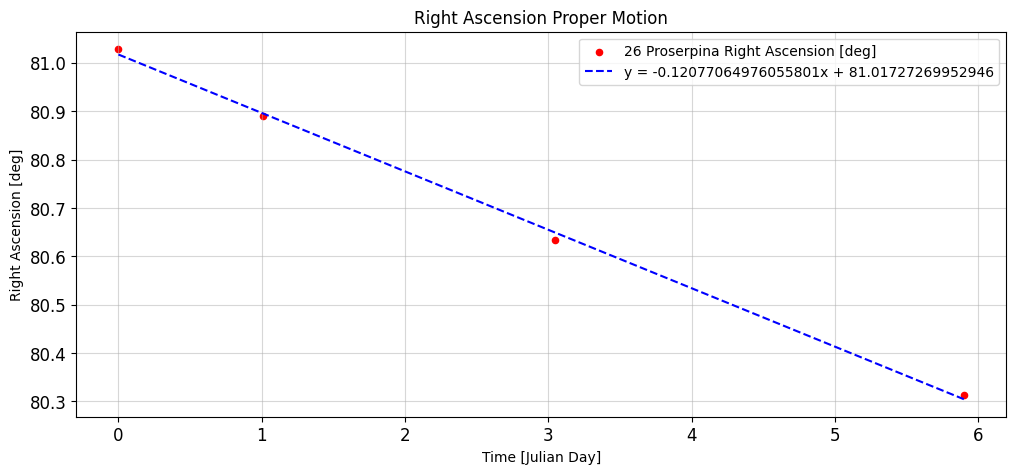

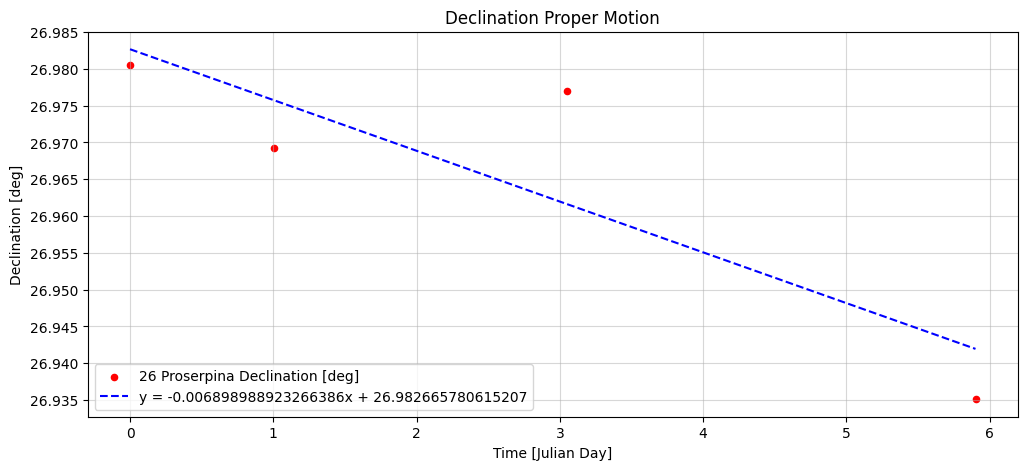

In [97]:
from astropy.time import Time
dates = [d1t1, d2t1, d3t1, d4t1]
times_dt = [Time(date).datetime for date in dates]
times_jd = [Time(date).jd for date in dates]
normalized_times_jd = times_jd - times_jd[0]

# Fit a line to the data 
coefficients_ra, residuals_ra, _, _, _ = np.polyfit(normalized_times_jd, proserpina_calculated_ra, 1, full=True)
coefficients_dec, residuals_dec, _, _, _ = np.polyfit(normalized_times_jd, proserpina_calculated_dec, 1, full=True)
ra_line = np.poly1d(coefficients_ra)
ra_rms = np.sqrt(residuals_ra/len(residuals_ra))
dec_rms = np.sqrt(residuals_dec/len(residuals_dec))
dec_line = np.poly1d(coefficients_dec)

fig = plt.figure(figsize=(12, 5))
plt.title("Right Ascension Proper Motion")
plt.xlabel("Time [Julian Day]")
plt.ylabel("Right Ascension [deg]")
plt.scatter(normalized_times_jd, proserpina_calculated_ra, s=20, color='red', label="26 Proserpina Right Ascension [deg]")
plt.plot(normalized_times_jd, ra_line(normalized_times_jd), color='blue', label = f"y = {coefficients_ra[0]}x + {coefficients_ra[1]}", ls='--')
plt.grid(alpha=0.5)
plt.legend()
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

fig = plt.figure(figsize=(12, 5))
plt.yticks(np.arange(26.9,27, 0.005))
plt.title("Declination Proper Motion")
plt.xlabel("Time [Julian Day]")
plt.ylabel("Declination [deg]")
plt.scatter(normalized_times_jd, proserpina_calculated_dec, s=20, color='red', label="26 Proserpina Declination [deg]")
plt.plot(normalized_times_jd, dec_line(normalized_times_jd), color='blue', label=f"y = {coefficients_dec[0]}x + {coefficients_dec[1]}", ls='--')
plt.legend(loc = 'lower left')
plt.grid(alpha=0.5)
plt.show()


In [103]:
print("RA RMS: ", ra_rms)
print("RA Residuals: ", residuals_ra)
print("DEC RMS: ", dec_rms)
print("DEC Residuals: ", residuals_dec)

print("Velocity in RA (deg/day): ", coefficients_ra[0])
print("Velocity in DEC (deg/day): ", coefficients_dec[0])

print("Velocity in RA (arcsec/min): ", (coefficients_ra[0]*3600)/(1440))
print("Velocity in DEC (arcsec/min): ", (coefficients_dec[0]*3600)/1440)
print("Celestial Velocity (arcsec/min): ", np.sqrt((coefficients_ra[0]*3600/1440)**2 + (coefficients_dec[0]*3600/1440)**2))

############### Sources of Error ####################
pixel_scale = 0.53 # arcsec/pixel
print("---- Error Propagation ----")
rmse_stars = np.sqrt(np.sum(std)**2/len(std))
print("RMSE Stars (pixel): ",rmse_stars)
print("RMSE Plate (pixel): ",rmse_fit)
rmse_stars_arcsec = pixel_scale*rmse_stars # arcsec
rmse_plate_arcsec = pixel_scale*rmse_fit # arcsec
rmse_stars_arces_min = rmse_stars_arcsec/10080
rmse_plate_arcsec_min = rmse_plate_arcsec/10080
print("RMS Stars (arcsec): ", rmse_stars_arcsec)
print("RMS Plate (arcsec): ", rmse_plate_arcsec)
print("RMS Asteroid (RA) (arcsec/min): ", ra_rms)
print("RMS Asteroid (DEC) (arcsec/min): ", dec_rms)
print("-----")
print("Final propogated error for velocity magnitude: ", np.sqrt(rmse_stars_arces_min**2 + rmse_plate_arcsec_min**2 + ra_rms**2 + dec_rms**2))



RA RMS:  [0.02073839]
RA Residuals:  [0.00043008]
DEC RMS:  [0.01813009]
DEC Residuals:  [0.0003287]
Velocity in RA (deg/day):  -0.12077064976055801
Velocity in DEC (deg/day):  -0.006898988923266386
Velocity in RA (arcsec/min):  -0.301926624401395
Velocity in DEC (arcsec/min):  -0.017247472308165965
Celestial Velocity (arcsec/min):  0.30241885163369364
---- Error Propagation ----
RMSE Stars (pixel):  0.12292951530732318
RMSE Plate (pixel):  0.38221647141495374
RMS Stars (arcsec):  0.06515264311288128
RMS Plate (arcsec):  0.2025747298499255
RMS Asteroid (RA) (arcsec/min):  [0.02073839]
RMS Asteroid (DEC) (arcsec/min):  [0.01813009]
-----
Final propogated error for velocity magnitude:  [0.02754599]
